<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-01-automl.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "AutoML"
bibliography:
  - refs/refs.bib
---

# Session plan: theory and coding

| Activity |
| --- |
| Theory 1: HPO, validation metrics, grid and random search |
| [Coding 1 (~15 min): Exercises 1-2](#coding-break-1) |
| Theory 2: CASH, search budgets, multi-fidelity methods, and FLAML |
| [Coding 2 (~15 min): Exercise 3](#coding-break-2) |
| Theory 3: Anytime performance, pipeline optimization, MLZero, and AutoML limitations |
| [Coding 3 (~15 min): Exercise 4](#coding-break-3) |


# The Problem: Hyperparameter Optimization

![Example of a hyperparameter optimization loop.](img/rf_hpo.svg)

- A learning algorithm (e.g., a random forest classifier) fits **parameters** of a model (e.g., the values of node splits) while training on data.
- **Hyperparameters** configure that fitting process (e.g., tree depth).


# The Problem: Hyperparameter Optimization

**Hyperparameter optimization** is the process of finding the best set of model hyperparameters. Given: 

- Training data $D_{\mathrm{tr}}$;
- A learning algorithm $A$ and a target $\mathcal L$;
- A hyperparameter search space $\Lambda$.

It solves

$$\lambda^* \in \arg\min_{\lambda\in\Lambda} f(\lambda), \qquad
f(\lambda)=\mathcal{L}_{D_{\mathrm{val}}}\!\left(A_\lambda(D_{\mathrm{tr}})\right).$$

Here $\mathcal L$ is a validation loss; for classification accuracy we can minimize $1-Accuracy$.

# HPO as an Optimizer-Learning-System Loop

![Optimizer proposes a configuration; the learning system trains and validates it and returns a loss. Source: Hutter and Vanschoren AutoML tutorial.](img/hpo.png)

The learning system fits model parameters.

- E.g., Neural network: connection weights and biases.

The optimizer changes hyperparameters: the distribution and bounds encode assumptions.

- E.g., Neural network: layers, activation functions, learning rate.
- Choose *target*, *metric*, and *hyperparameter* ranges before running the optimizer. 
- **A poor search space can defeat any optimizer**.



In [1]:
#| echo: false
# Install missing packages, including FLAML's optional learners.
import importlib.util
import subprocess
import sys

packages = {
    "flaml": "flaml[automl]", "xgboost": "flaml[automl]", "lightgbm": "flaml[automl]",
    "matplotlib": "matplotlib", "numpy": "numpy", "pandas": "pandas",
    "scipy": "scipy", "sklearn": "scikit-learn",
}
missing = sorted({package for module, package in packages.items()
                  if importlib.util.find_spec(module) is None})
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

time_budget = 30  # Seconds per main FLAML run; use 5 for a quick smoke run.


In [2]:
#| echo: false
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import (
    GridSearchCV,
    HalvingRandomSearchCV,
    PredefinedSplit,
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.get_cmap("tab10").colors)


In [3]:
#| echo: false
def evaluate_classifier(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_eval, y_pred),
        "f1": f1_score(y_eval, y_pred),
    }


# FLAML minimizes loss; log balanced accuracy alongside it.
def flaml_balanced_accuracy(X_val, y_val, estimator, *args, **kwargs):
    score = balanced_accuracy_score(y_val, estimator.predict(X_val))
    return 1 - score, {"balanced_accuracy": score}


# Get the Dataset

[Adult Census Income](https://archive.ics.uci.edu/dataset/2/adult). [@becker1996adult]

In [4]:
#| echo: false
adult_df = pd.read_csv(
    "https://archive.ics.uci.edu/static/public/2/data.csv", na_values="?", skipinitialspace=True,
).dropna()
adult_df.columns = adult_df.columns.str.strip().str.lower().str.replace("-", "_", regex=False)
adult_df["income"] = adult_df["income"].str.replace(".", "", regex=False).str.strip()
adult_df = adult_df.sample(n=min(8000, len(adult_df)), random_state=RANDOM_STATE).reset_index(drop=True)
adult_source = "UCI Adult Census Income"
adult_df.head()


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,28,Private,319768,Masters,14,Married-civ-spouse,Sales,Husband,White,Male,0,0,45,France,>50K
1,60,Private,120067,9th,5,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,45,United-States,<=50K
2,43,Private,211517,Some-college,10,Never-married,Adm-clerical,Not-in-family,White,Male,0,1669,45,United-States,<=50K
3,35,State-gov,210866,HS-grad,9,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,United-States,<=50K
4,36,Private,320811,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,>50K


# Get the Dataset

In [5]:
adult_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             8000 non-null   int64
 1   workclass       8000 non-null   str  
 2   fnlwgt          8000 non-null   int64
 3   education       8000 non-null   str  
 4   education_num   8000 non-null   int64
 5   marital_status  8000 non-null   str  
 6   occupation      8000 non-null   str  
 7   relationship    8000 non-null   str  
 8   race            8000 non-null   str  
 9   sex             8000 non-null   str  
 10  capital_gain    8000 non-null   int64
 11  capital_loss    8000 non-null   int64
 12  hours_per_week  8000 non-null   int64
 13  native_country  8000 non-null   str  
 14  income          8000 non-null   str  
dtypes: int64(6), str(9)
memory usage: 937.6 KB


In [6]:
#| echo: false
X_cls = adult_df.drop(columns=["income"])
y_cls = (adult_df["income"] == ">50K").astype(int)
assert y_cls.nunique() == 2, "Classification requires two target classes."

X_cls_dev, X_cls_test, y_cls_dev, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls,
)

X_cls_train, X_cls_val, y_cls_train, y_cls_val = train_test_split(
    X_cls_dev, y_cls_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cls_dev
)

numeric_cls = X_cls_train.select_dtypes(include=np.number).columns.tolist()
categorical_cls = [c for c in X_cls_train.columns if c not in numeric_cls]


# Set the Target: Balanced Accuracy

In [7]:
adult_df["income"].value_counts(normalize=True).rename("target_share").round(3)

income
<=50K    0.745
>50K     0.255
Name: target_share, dtype: float64

For $C$ classes, balanced accuracy is the mean recall across classes:

- A majority-only classifier have high accuracy but balanced accuracy of 0.5.
- $\mathrm{BA}=\frac{1}{C}\sum_{c=1}^{C}\frac{TP_c}{TP_c+FN_c}$

# Fixed Random-Forest Baseline

In [8]:
# Fit preprocessing once on training rows; every method receives these same arrays.
classification_preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cls),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cls),
])
X_train_model = classification_preprocess.fit_transform(X_cls_train)
X_val_model = classification_preprocess.transform(X_cls_val)
classification_baseline = RandomForestClassifier(
    n_estimators=144, # trees
    max_depth=4, # depth of each tree
    min_samples_leaf=5, # minimum samples per leaf
    max_features="sqrt", # number of features to consider at each split
    class_weight="balanced", # handle class imbalance
    random_state=RANDOM_STATE, n_jobs=1,
)
started = time.perf_counter()
classification_baseline.fit(X_train_model, y_cls_train)
baseline_elapsed = time.perf_counter() - started
classification_baseline_scores = evaluate_classifier(classification_baseline, X_val_model, y_cls_val)


In [9]:
#| echo: false
comparison_rows = {"baseline": {
    "method": "baseline", "classifier": type(classification_baseline).__name__,
    "elapsed_s": baseline_elapsed, **classification_baseline_scores,
}}
pd.DataFrame(comparison_rows.values()).round(3)

,method,classifier,elapsed_s,accuracy,balanced_accuracy,f1
0,baseline,RandomForestClassifier,0.48,0.735,0.783,0.628


# Grid Search: Enumerate the Cartesian Product of Hyperparameters

![Grid search](img/remote/grid-search.png)

# Grid Search: Enumerate the Cartesian Product of Hyperparameters

For each of $d$ hyperparameters, choose a set of values $X_j$.

**Grid search** evaluates $N_{\mathrm{grid}}=\prod_{j=1}^d |X_j|$ configurations.

> For a random forest, 4 depths × 3 leaf sizes × 5 tree counts means 60 candidates, or 300 fits with 5-fold CV.

- Resolution is fixed by the grid: values between grid points are never tried.
- Adding an unimportant dimension multiplies the work.

```python
param_grid = {"max_depth": [2, 8, 24], "min_samples_leaf": [1, 5, 20]}
GridSearchCV(rf_estimator, param_grid, cv=holdout, scoring="balanced_accuracy")
```

# Random Search: Sample Random Hyperparameter Configurations

![Random search](img/remote/random-search.png)


# Random Search: Sample Random Hyperparameter Configurations

Choose a sampling distribution $p(\lambda)$, draw and evaluate $N_{rnd}$ independent configurations.

$$\lambda_1,\ldots,\lambda_{N_{rnd}}\sim p(\lambda),\qquad \widehat\lambda\in\arg\min_{\lambda_i}\widehat f(\lambda_i).$$

<details>
<summary>Answer</summary>
Independent trials can be parallelized.
Previous evaluations are ignored, so the search may waste time in unpromising regions.
</details>

```python
param_random = {
    "max_depth": randint(2, 25),
    "min_samples_leaf": randint(1, 21),
}
RandomizedSearchCV(rf_estimator, param_random, n_iter=9, cv=holdout, scoring="balanced_accuracy", random_state=RANDOM_STATE)
```

:::{.fragment}
It does not use earlier scores to propose later candidates. *Pros*? *Cons*?
:::

# Why Can Random Search Work Well?

If only one of two hyperparameters matters, a 3 × 3 grid spends nine trials on only three values of the important parameter.

- Nine random samples could explore nine distinct values of each hyperparameter.
- The advantage grows when a high-dimensional space has only a few influential dimensions.

Let a useful region have probability mass $p$. With independent trials [@bergstra2012random]

$$P(\text{at least one useful configuration in }N\text{ trials})=1-(1-p)^N.$$

- For $p=0.05$, 59 trials give about a 95% chance of hitting that region.
- This is not a guarantee of generalization or of finding the global optimum.

# Why Can Random Search Work Well?

The probability depends on the region's mass under the sampling distribution.

| Independent trials | Hit a region of mass 5% | Hit a region of mass 1% |
| --- | --- | --- |
| 20 | 64% | 18% |
| 60 | 95% | 45% |
| 300 | >99.9% | 95% |

The example depends strongly on the first coordinate. Compare a fixed nine-point grid with 1,000 repetitions of nine random trials.

Grid (9 trials, 3 distinct l1 values): loss = 0.803. Random (9 trials, 9 distinct l1 values): median loss = 0.096
Random search beats the grid in 98% of the repetitions


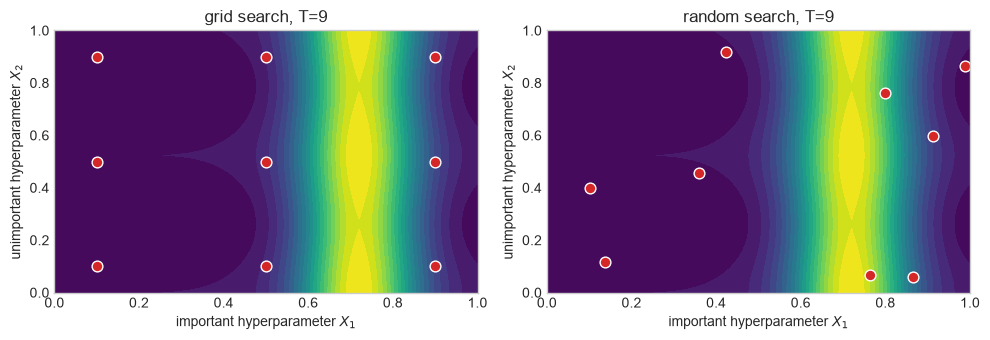

In [10]:
#| echo: false
def toy_objective(l1, l2):
    """Validation loss: depends strongly on l1, weakly on l2. Minimum near l1=0.72."""
    return 1 - np.exp(-((l1 - 0.72) ** 2) / 0.02) + 0.05 * np.sin(6 * l2) ** 2


rng = np.random.default_rng(RANDOM_STATE)
T = 9
side = np.linspace(0.1, 0.9, int(np.sqrt(T)))
G1, G2 = np.meshgrid(side, side)
grid_best = toy_objective(G1, G2).min()

random_best = np.array([
    toy_objective(rng.uniform(0, 1, T), rng.uniform(0, 1, T)).min() for _ in range(1000)
])

print(f"Grid ({T} trials, {len(side)} distinct l1 values): loss = {grid_best:.3f}. Random ({T} trials, {T} distinct l1 values): median loss = {np.median(random_best):.3f}")
print(f"Random search beats the grid in {(random_best < grid_best).mean():.0%} of the repetitions")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
for ax, (title, p1, p2) in zip(axes, [("grid", G1.ravel(), G2.ravel()),
                                      ("random", rng.uniform(0, 1, T), rng.uniform(0, 1, T))]):
    ax.contourf(xx, yy, toy_objective(xx, yy), levels=20, cmap="viridis_r")
    ax.scatter(p1, p2, c="tab:red", edgecolor="white", s=60)
    ax.set_title(f"{title} search, T={T}")
    ax.set_xlabel("important hyperparameter $X_1$")
    ax.set_ylabel("unimportant hyperparameter $X_2$")
plt.tight_layout()
plt.show()

# Example: Four-Parameter Random Forest 

```python
param_grid = {
    "max_depth": [2, 4], "min_samples_leaf": [16, 24], "max_features": [0.15, 1.0], "max_samples": [0.5, 1.0],
}
param_random = {
    "max_depth": randint(2, 5), "min_samples_leaf": randint(1, 25), "max_features": uniform(0.15, 0.85), "max_samples": uniform(0.5, 0.5),
}
```

In [11]:
#| echo: false
# SearchCV uses exactly the existing holdout, with no additional folds.
X_search = np.concatenate([X_train_model, X_val_model])
y_search = np.concatenate([y_cls_train, y_cls_val])
holdout = PredefinedSplit(np.r_[
    np.full(len(y_cls_train), -1), np.zeros(len(y_cls_val), dtype=int)
])
RF_TREES = 144  # Full resource for grid, random search, and halving finalists.
N_RANDOM = 18
rf_estimator = RandomForestClassifier(
    n_estimators=RF_TREES, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
)
# Deliberately restricted grid: shallow trees and large leaves can underfit.
param_grid = {
    "max_depth": [2, 4], "min_samples_leaf": [16, 24], "max_features": [0.15, 1.0], "max_samples": [0.5, 1.0],
}
param_random = {
    "max_depth": randint(2, 5), "min_samples_leaf": randint(1, 25), "max_features": uniform(0.15, 0.85), "max_samples": uniform(0.5, 0.5),
}
# refit=False prevents SearchCV from training on the combined train+validation data.
rf_searches = {
    "grid": GridSearchCV(rf_estimator, param_grid, cv=holdout,
                         scoring="balanced_accuracy", refit=False, n_jobs=1, error_score="raise"),
    "random": RandomizedSearchCV(rf_estimator, param_random, n_iter=N_RANDOM, cv=holdout,
        scoring="balanced_accuracy", refit=False, n_jobs=1,
        random_state=RANDOM_STATE, error_score="raise"),
}
rf_search_rows = {}


def fit_search(name, search):
    started = time.perf_counter()
    search.fit(X_search, y_search)
    # Fit the selected configuration on TRAINING rows only, at full resource.
    model = clone(rf_estimator).set_params(**search.best_params_)
    model.fit(X_train_model, y_cls_train)
    elapsed = time.perf_counter() - started
    scores = evaluate_classifier(model, X_val_model, y_cls_val)
    row = {
        "method": name, "classifier": type(model).__name__, "elapsed_s": elapsed,
        "evaluations": len(search.cv_results_["params"]),
        "search_trees": sum(p.get("n_estimators", RF_TREES) for p in search.cv_results_["params"]),
        **scores,
    }
    rf_search_rows[name] = row
    comparison_rows[name] = row


for name, search in rf_searches.items():
    fit_search(name, search)
pd.DataFrame(rf_search_rows.values()).round(4)


,method,classifier,elapsed_s,evaluations,search_trees,accuracy,balanced_accuracy,f1
0,grid,RandomForestClassifier,9.8357,16,2304,0.7619,0.8055,0.6564
1,random,RandomForestClassifier,9.8775,18,2592,0.7644,0.8048,0.6570


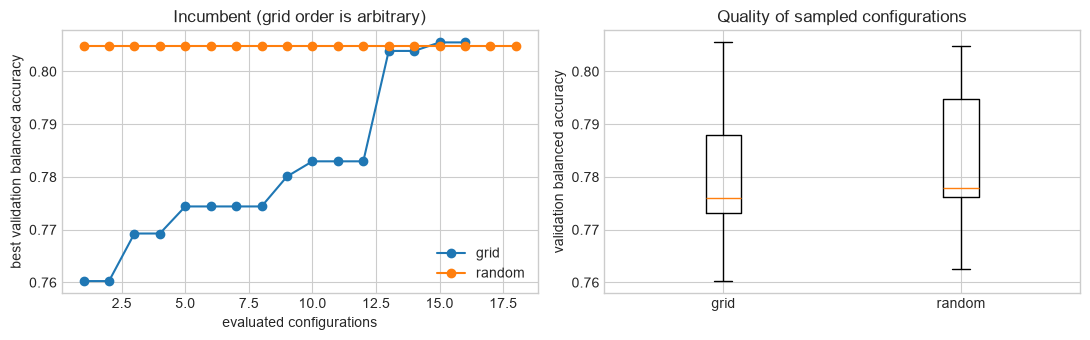

In [12]:
#| echo: false
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, search in rf_searches.items():
    scores = search.cv_results_["mean_test_score"]
    axes[0].plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores), marker="o", label=name)
axes[0].set(xlabel="evaluated configurations", ylabel="best validation balanced accuracy", title="Incumbent (grid order is arbitrary)")
axes[0].legend()
axes[1].boxplot([search.cv_results_["mean_test_score"] for search in rf_searches.values()],
                tick_labels=list(rf_searches))
axes[1].set(ylabel="validation balanced accuracy", title="Quality of sampled configurations")
plt.tight_layout()
plt.show()

# Coding break 1: Exercises 1-2 (~15 minutes)

<a id="coding-break-1"></a>

Run the [setup](#coding-exercise-setup), then implement [Exercises 1-2](#coding-exercises-1).


# From HPO to AutoML

<a id="theory-block-2"></a>

**Automated Machine Learning (AutoML)** automates choices when building and evaluating an ML solution.

- While HPO fixes the learning algorithm, AutoML also chooses the algorithm.
- The user defines the task, search space, metric and budget. 

# CASH: Combined Algorithm Selection and Hyperparameter Optimization

Let $\mathcal A=\{A_1,\ldots,A_M\}$ be candidate algorithms and $\Lambda_a$ the hyperparameter space of $A_a$. The **CASH** problem [@thornton2013auto] is

$$ (a^*,\lambda^*)\in\arg\min_{a\in\{1,\ldots,M\},\;\lambda\in\Lambda_a}
\mathcal L_{D_{\mathrm{val}}}\!\left(A_{a,\lambda}(D_{\mathrm{tr}})\right). $$

CASH jointly selects the algorithm and its hyperparameters under a resource budget.

- CASH inherits HPO's expensive evaluations and adds learner-level allocation: **which algorithm deserves the next unit of budget?**
- Its domain is a conditional union $\bigcup_a\{a\}\times\Lambda_a$, rather than one rectangular grid.
- The hyperparameter space is a conditional tree or graph, not a Cartesian product of every learner's settings.
- A **root hyperparameter** selects the learner, activating only its associated space $\Lambda_a$.

> $A_1$ is forest and activates $\Lambda_1 = \{depth \in [3, 5], \#trees \in [10, 100]\}$ tree-related settings.
> 
> $A_2$ is logistic regression activates $\Lambda_2$ regularization settings.
> 
> $A_{1, \{depth=3, \#trees=100\}}$ is a random forest with 100 trees of maximum depth 3 applied to $D_{tr}$.


# Search Under a Budget



# The Budget Is Part of the Problem

Budget:

- A **trial/instance/configuration budget** limits the number of candidates.
- A **time budget** limits elapsed time (include preprocessing and search overhead).

They are different: a deep forest can cost much more than a small linear model. 

For a sequential search history $H_N$ a simplified resource constraint is $\sum_{i=1}^N c(A_{\lambda_i},r_i)+c_{\mathrm{overhead}}\le B.$

Here $r_i$ is *fidelity*, $c$ is cost, and $B$ is the total budget.

- The optimizer chooses what to evaluate, at what fidelity (i.e., resource level; for example, sample size or epochs), and when to stop.
- Compare methods with the same data, metric, hardware, and resource accounting. *Why*?

# Bayesian Optimization: Choose the Next Configuration

Random search ignores completed trials. Bayesian optimization uses their results to choose what to try next [@snoek2012practical].

- A **surrogate** predicts validation loss and uncertainty for untested configurations.
- An **acquisition function** balances exploiting promising regions and exploring uncertain ones.
- Evaluate a configuration → update the surrogate → propose the next configuration → repeat until the budget is exhausted.

The surrogate can be a machine learning model, such as a random forest as in SMAC [@hutter2011sequential]. 

- It predicts configuration quality, rather than the dataset's target.

<div></div>
:::: {.columns}
::: {.column width="33%"}
![Grid search](img/remote/grid-search.png){height=180px}
:::
::: {.column width="33%"}
![Random search](img/remote/random-search.png){height=180px}
:::
::: {.column width="33%"}
![Bayesian optimization (TPE)](img/remote/bayesian-optimization-tpe.png){height=180px}
:::
::::


# Bayesian Optimization: Surrogate and Next Evaluation

C:\Users\matteo.francia5\AppData\Roaming\Python\Python314\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


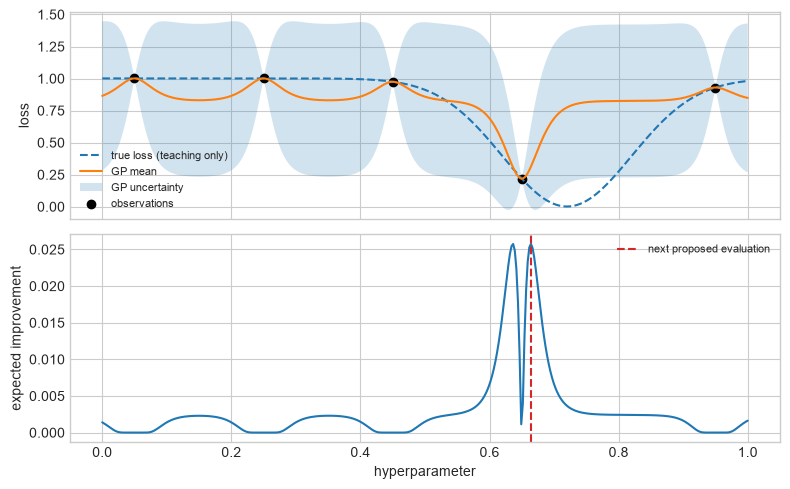

In [13]:
#| echo: false
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

bo_x = np.array([0.05, 0.25, 0.45, 0.65, 0.95]).reshape(-1, 1)
bo_y = toy_objective(bo_x.ravel(), 0.5)
bo_gp = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0, (0.01, 10)) * Matern(length_scale=0.15, length_scale_bounds=(0.03, 1.0), nu=2.5),
    alpha=1e-6, normalize_y=True, random_state=RANDOM_STATE,
)
bo_gp.fit(bo_x, bo_y)
bo_candidates = np.linspace(0, 1, 400).reshape(-1, 1)
bo_mean, bo_std = bo_gp.predict(bo_candidates, return_std=True)
bo_delta = bo_y.min() - bo_mean - 0.01
bo_z = np.divide(bo_delta, bo_std, out=np.zeros_like(bo_delta), where=bo_std > 0)
bo_ei = np.where(bo_std > 0, bo_delta * norm.cdf(bo_z) + bo_std * norm.pdf(bo_z), np.maximum(bo_delta, 0))
bo_next = int(np.argmax(bo_ei))
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(bo_candidates.ravel(), toy_objective(bo_candidates.ravel(), 0.5), "--", label="true loss (teaching only)")
axes[0].plot(bo_candidates.ravel(), bo_mean, label="GP mean")
axes[0].fill_between(bo_candidates.ravel(), bo_mean - 1.96 * bo_std, bo_mean + 1.96 * bo_std, alpha=0.2, label="GP uncertainty")
axes[0].scatter(bo_x.ravel(), bo_y, color="black", label="observations")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=8)
axes[1].plot(bo_candidates.ravel(), bo_ei)
axes[1].axvline(bo_candidates[bo_next, 0], color="tab:red", linestyle="--", label="next proposed evaluation")
axes[1].set(xlabel="hyperparameter", ylabel="expected improvement")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Successive Halving: Allocate Resources

Choosing a configuration is one decision, deciding how much resource to spend evaluating it is another.

**Fidelity** is the resource level: for example, fewer training rows or epochs give a cheaper evaluation.

- Successive halving increases resources for the surviving candidates [@jamieson2016nonstochastic].

| Round | Candidates | Resource per candidate | Total resource |
| --- | --- | --- | --- |
| 0 | 18 | 16 trees | 288 trees |
| 1 | 6 | 48 trees | 288 trees |
| 2 | 2 | 144 trees | 288 trees |



# Hyperband: Vary the Starting Allocation

Successive halving fixes the starting allocation: the number of candidates and their initial resource.

- Hyperband varies that tradeoff across several halving brackets [@li2018hyperband].
  - Start many candidates cheaply, or fewer candidates with more resources each.
  - Low-fidelity rankings can be misleading: a model that learns slowly may be discarded too early.
- Low fidelity is useful when it preserves enough of the high-fidelity ranking. 
  - ... It can also discard slow-starting or data-hungry models.

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-1.png)



# Multi-Fidelity and Combined Search

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-2.png)

# Demo: Successive Halving on the Same Random Forest Space

Compare 18 initial configurations on the same training/validation rows.

- Halving allocates trees over three rounds:
  - Increase tree count: 16 → 48 → 144.
  - Retain approximately one third: 18 → 6 → 2 candidates.
- Random search gives every candidate 144 trees.

In [14]:
halving = HalvingRandomSearchCV(
    rf_estimator, param_random, n_candidates=N_RANDOM, factor=3,
    resource="n_estimators", min_resources=16, max_resources=RF_TREES,
    cv=holdout, scoring="balanced_accuracy", refit=False, n_jobs=1,
    random_state=RANDOM_STATE, error_score="raise",
)
fit_search("halving", halving)

In [15]:
#| echo: false
#| output: false
pd.DataFrame({
    "round": range(halving.n_iterations_),
    "candidates": halving.n_candidates_,
    "trees_per_candidate": halving.n_resources_,
    "total_search_trees": np.array(halving.n_candidates_) * np.array(halving.n_resources_),
})


,round,candidates,trees_per_candidate,total_search_trees
0,0,18,16,288
1,1,6,48,288
2,2,2,144,288


In [16]:
#| echo: false
search_comparison = pd.DataFrame(rf_search_rows.values()).set_index("method")
display(search_comparison.round(4))
print(f"Halving speedup over random: {search_comparison.loc['random', 'elapsed_s'] / search_comparison.loc['halving', 'elapsed_s']:.2f}x")


,classifier,elapsed_s,evaluations,search_trees,accuracy,balanced_accuracy,f1
method,,,,,,,
grid,RandomForestClassifier,9.8357,16,2304,0.7619,0.8055,0.6564
random,RandomForestClassifier,9.8775,18,2592,0.7644,0.8048,0.6570
halving,RandomForestClassifier,4.9534,26,864,0.7644,0.8048,0.6570


Halving speedup over random: 1.99x


# FLAML: Search and Resource Allocation

FLAML is an AutoML system that selects learners and hyperparameters under a budget [@wang2021flaml].

- **Configuration selection:** like BO, it uses previous results [@wu2021frugal].
- **Resource allocation:** like Hyperband, FLAML adapts resource allocation.
    - Adjust training sample size.
    - Allocate time across learners using observed cost and improvement.

In [17]:
from flaml import AutoML
classification_automl = AutoML()
classification_started_at = time.perf_counter()
classification_automl.fit(
    X_train=X_train_model, y_train=y_cls_train,
    X_val=X_val_model, y_val=y_cls_val,
    eval_method="holdout",
    retrain_full=False,
    task="classification", metric=flaml_balanced_accuracy,
    time_budget=time_budget,
    log_file_name=f"flaml_main_classification_balanced_accuracy_{time_budget}s.log", seed=RANDOM_STATE, verbose=1, n_jobs=1,
)
classification_elapsed = time.perf_counter() - classification_started_at
print(f"Selected learner: {classification_automl.best_estimator}; classifier: {type(classification_automl.model.estimator).__name__}")
print("Selected hyperparameters:", classification_automl.best_config)

Selected learner: lgbm; classifier: LGBMClassifier
Selected hyperparameters: {'n_estimators': 34, 'num_leaves': 36, 'min_child_samples': 6, 'learning_rate': np.float64(0.23881309587121854), 'log_max_bin': 7, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.020536646451193807), 'reg_lambda': np.float64(0.02276574312098569)}


# FLAML: Search and Resource Allocation

In [18]:
#| echo: false
classification_automl_scores = evaluate_classifier(classification_automl, X_val_model, y_cls_val)
comparison_rows["FLAML"] = {
    "method": "FLAML", "classifier": type(classification_automl.model.estimator).__name__,
    "elapsed_s": classification_elapsed, **classification_automl_scores,
}
# All scores use the SAME validation rows and encoded columns.
classification_comparison = pd.DataFrame(comparison_rows.values())[[
    "method", "classifier", "elapsed_s", "accuracy", "balanced_accuracy", "f1"
]].set_index("method")
classification_comparison.round(4)


,classifier,elapsed_s,accuracy,balanced_accuracy,f1
method,,,,,
baseline,RandomForestClassifier,0.4798,0.7350,0.7826,0.6281
grid,RandomForestClassifier,9.8357,0.7619,0.8055,0.6564
random,RandomForestClassifier,9.8775,0.7644,0.8048,0.6570
halving,RandomForestClassifier,4.9534,0.7644,0.8048,0.6570
FLAML,LGBMClassifier,30.1429,0.8712,0.8222,0.7406


# Inspect FLAML's Conditional CASH Space


In [19]:
from flaml.automl.model import RandomForestEstimator
from flaml.automl.task.factory import task_factory
print("Default learners for this run:", classification_automl.estimator_list)

Default learners for this run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']


In [20]:
#| echo: false
def describe_space(space):
    rows = []
    for name, spec in space.items():
        domain = spec["domain"]
        if hasattr(domain, "categories"): values = str(list(domain.categories))
        elif hasattr(domain, "lower") and hasattr(domain, "upper"):
            sampler = domain.get_sampler() if hasattr(domain, "get_sampler") else None
            values = f"[{domain.lower}, {domain.upper}] ({type(sampler).__name__})"
        else: values = str(domain)
        rows.append({"hyperparameter": name, "domain": values, "init_value": spec.get("init_value"), "low_cost_init_value": spec.get("low_cost_init_value")})
    return pd.DataFrame(rows)

In [21]:
describe_space(RandomForestEstimator.search_space(data_size=X_train_model.shape, task=task_factory("classification", X_train_model, y_cls_train)))

,hyperparameter,domain,init_value,low_cost_init_value
0,n_estimators,"[4, 2048] (_LogUniform)",4.000000,4.0
1,max_features,"[0.09901475429766744, 1.0] (_LogUniform)",0.099015,NaN
2,max_leaves,"[4, 2400] (_LogUniform)",4.000000,4.0
3,criterion,"['gini', 'entropy']",NaN,NaN


# Coding break 2: Exercise 3 (~15 minutes)

<a id="coding-break-2"></a>

Go to [Exercise 3](#coding-exercises-2).


# Anytime Performance Under a Budget

<a id="theory-block-3"></a>

Define the incumbent curve for completed trials $f^*(\tau)=\min\{f_i:t_i\le\tau\},\qquad \tau\le B.$

- Each trial has a validation loss $f_i$ and a completion time $t_i$.
- The curve shows how quickly the optimizer finds better configurations.

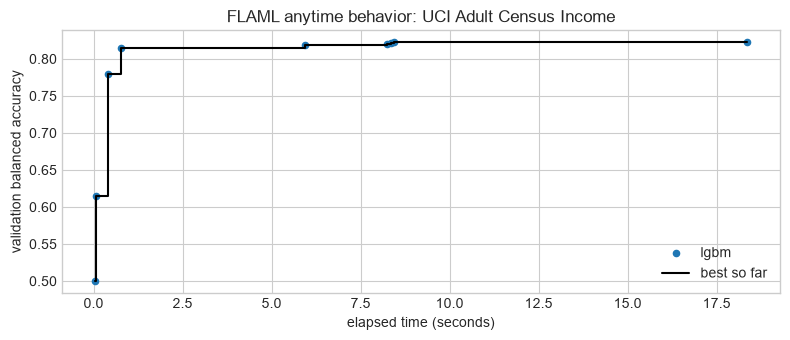

In [22]:
#| echo: false
from flaml.automl.data import get_output_from_log
log_path = f"flaml_main_classification_balanced_accuracy_{time_budget}s.log"
time_history, best_loss_history, loss_history, config_history, _ = get_output_from_log(
    filename=log_path, time_budget=float("inf")
)
learners = [record["Current Learner"] for record in config_history]
fig, ax = plt.subplots(figsize=(8, 3.5))
for learner in sorted(set(learners)):
    idx = [i for i, name in enumerate(learners) if name == learner]
    ax.scatter(np.asarray(time_history)[idx], 1 - np.asarray(loss_history)[idx], s=20, label=learner)
ax.step(time_history, 1 - np.asarray(best_loss_history), where="post", color="black", label="best so far")
ax.set(xlabel="elapsed time (seconds)", ylabel="validation balanced accuracy", title=f"FLAML anytime behavior: {adult_source}")
ax.legend()
plt.tight_layout()
plt.show()

Increasing a budget changes the search opportunity.

- Tradeoff of validation quality and elapsed time: if two budgets give similar validation scores, is the extra compute time justified?
- A system that is excellent after two hours may not be the best choice for an interactive workflow that allows only two minutes.

# From CASH to End-to-End Pipeline Optimization

So far, we fixed data cleaning, category encoding, feature availability, and validation design, then searched over learners. 

- End-to-end pipeline optimization also searches over the **structure and operations** that turn raw data into predictions.

- Describe a pipeline using its conditional settings $\theta\in\Theta_s$ and the steps $\mathcal S(C)$ allowed by constraints $C$.

$$ (s^*,\theta^*)\in\arg\min_{s\in\mathcal S(C),\;\theta\in\Theta_s}
\widehat{\mathcal L}_{\mathrm{val}}\!\left(\operatorname{Fit}(P_{s,\theta},D_{\mathrm{tr}})\right),
\qquad c_{\mathrm{search}}\le B. $$

![End-to-End Pipeline Optimization](./img/phdslides_218.png)

# Why Full Pipeline Search Is Harder

[@giovanelli2021effective] study transformations and combinations of transformations as **pipeline prototypes**.

- E.g., which step types are present and in which order.
- Unfortunately, no pipeline prototype is always best.
    - **Data quality:** deletion, imputation, and feature construction can change who is represented and what the model learns.
    - **Constraints:** accuracy competes with latency, fairness, interpretability, and resource limits; some pipelines are inadmissible even if accurate.
    - **Dependencies:** scaling matters for some learners, not for others.
    - ...
- **Exercise:** discuss admissible orders for feature selection/resampling/imputation.

# MLZero: Agents Build and Repair ML Workflows

[@fang2025mlzero] uses LLM-powered agents to automate workflows across data modalities.

![MLZero](img/remote/mlzero-framework.jpg)

- Agents generate code, execute it, inspect failures, and revise the workflow.
- Memory helps reduce hallucinated or outdated API calls:
  - Semantic memory supplies reusable knowledge.
  - Episodic memory retains earlier attempts and errors.

# Wrap-Up

# What AutoML Automates

AutoML can automate repetitive parts of modeling:

- trying candidate learners;
- allocating trials;
- tuning hyperparameters;
- returning a strong baseline.

# What AutoML Does Not Automate

You still need to:

- define the problem and target;
- check for leakage;
- assess fairness;
- monitor the deployed model;
- decide whether the model should be used at all.

# Further Reading (BIG's research on this topic)

- HAMLET [@francia2023hamlet].
- AutoClues [@francia2024autoclues].
- AGE-ML [@matteini2026agentic].


# Coding break 3: Exercise 4 (~15 minutes)

<a id="coding-break-3"></a>

Go to [Exercise 4](#coding-exercises-3).


# Exercises

<a id="coding-exercise-setup"></a>

# Setup


In [23]:
from sklearn.linear_model import LogisticRegression
from scipy.stats import loguniform
from flaml import AutoML

# Provided data preparation only; create the estimators in the exercises.
unscaled_preprocess = clone(classification_preprocess).set_params(num="passthrough")
X_train = unscaled_preprocess.fit_transform(X_cls_train)
X_val = unscaled_preprocess.transform(X_cls_val)
X_train_scaled, X_val_scaled = X_train_model, X_val_model
y_train, y_val = y_cls_train, y_cls_val

# The holdout marks training rows as -1 and validation rows as 0.
X_search_raw = np.concatenate([X_train, X_val])
X_search_scaled = np.concatenate([X_train_scaled, X_val_scaled])
y_search = np.concatenate([y_train, y_val])


# Exercise 1: Logistic Regression with Grid vs Random Search

<a id="coding-exercises-1"></a>

Train logistic regression on unscaled data, then compare grid and random search.

Which search performed better with the same number of evaluations?


In [24]:
# 1. Create and fit a default logistic-regression classifier.
#    Start with solver="liblinear", max_iter=300, random_state=42.
# logistic = LogisticRegression(...)
# logistic.fit(..., ...)

# 2. Evaluate on validation rows, not training rows. Note convergence warnings.
# raw_default_score = balanced_accuracy_score(y_val, logistic.predict(...))

# 3. Choose five C values for the grid and a distribution for random search.
#    C is inverse regularization strength: smaller C means stronger regularization.
#    Hint: np.logspace(-2, 2, 5) spans 0.01 to 100; loguniform samples across orders of magnitude.
#    Keep the same bounds for both spaces and all other estimator settings fixed.
# grid_space = {"C": ...}
# random_space = {"C": loguniform(..., ...)}

# 4. Create both searches. Use the existing holdout and five random trials.
#    refit=False keeps validation rows out of the final training fit.
# grid = GridSearchCV(logistic, grid_space, cv=holdout,
#                     scoring="balanced_accuracy", refit=False)
# random = RandomizedSearchCV(logistic, random_space, n_iter=5, cv=holdout,
#                             scoring="balanced_accuracy", refit=False, random_state=42)

# 5. Fit on the combined arrays: holdout identifies the training/validation rows.
# grid.fit(..., y_search)
# random.fit(..., y_search)
# print("Default:", raw_default_score)
# print("Grid:", grid.best_score_, grid.best_params_)
# print("Random:", random.best_score_, random.best_params_)


# Exercise 2: HPO vs Standardization

Repeat the comparison on standardized data.

- Does standardization alone beat tuning on unscaled data?
- Does combining both help further?


In [25]:
# 1. Clone the default estimator: preserve its settings and fit it on standardized training data.
# logistic_scaled = clone(logistic)
# logistic_scaled.fit(..., ...)
# scaled_default_score = balanced_accuracy_score(y_val, logistic_scaled.predict(...))

# 2. Clone each search to keep its space, evaluation count, and seed fixed.
# grid_scaled = clone(grid)
# random_scaled = clone(random)
# grid_scaled.fit(X_search_scaled, ...)
# random_scaled.fit(X_search_scaled, ...)

# 3. Compare the six scores: default/grid/random, with and without standardization.
# print("Unscaled:", raw_default_score, grid.best_score_, random.best_score_)
# print("Standardized:", scaled_default_score, grid_scaled.best_score_, random_scaled.best_score_)
#    Compare default -> tuned within each row to assess HPO.
#    Compare unscaled -> standardized within each method to assess the representation.


# Coding session 1 solution

<details>
<summary>Show the solution</summary>

```python
# Exercise 1: default model, then two searches on unscaled data.
logistic = LogisticRegression(solver="liblinear", max_iter=300, random_state=42)
logistic.fit(X_train, y_train)
raw_default_score = balanced_accuracy_score(y_val, logistic.predict(X_val))

grid = GridSearchCV(logistic, {"C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=holdout, scoring="balanced_accuracy", refit=False)
grid.fit(X_search_raw, y_search)
random = RandomizedSearchCV(logistic, {"C": loguniform(0.001, 100)}, n_iter=5, cv=holdout, scoring="balanced_accuracy", refit=False, random_state=42)
random.fit(X_search_raw, y_search)
print("Grid:", grid.best_score_, grid.best_params_)
print("Random:", random.best_score_, random.best_params_)

# Exercise 2: repeat on standardized data, keeping settings fixed.
logistic_scaled = clone(logistic).fit(X_train_scaled, y_train)
scaled_default_score = balanced_accuracy_score(y_val, logistic_scaled.predict(X_val_scaled))
grid_scaled = clone(grid).fit(X_search_scaled, y_search)
random_scaled = clone(random).fit(X_search_scaled, y_search)
print("              Def  Grid Rnd")
print("Unscaled:    ", round(raw_default_score, 2), round(grid.best_score_, 2), round(random.best_score_, 2))
print("Standardized:", round(scaled_default_score, 2), round(grid_scaled.best_score_, 2), round(random_scaled.best_score_, 2))
```

</details>


# Exercise 3: AutoML Under Different Time Budgets

<a id="coding-exercises-2"></a>

Compare AutoML with 5-, 15-, and 30-second budgets against tuned logistic regression.

Does more time improve performance? Does AutoML outperform tuned logistic regression? Independent runs need not improve monotonically with budget.


In [26]:
# 1. Start an empty score list, then create a fresh AutoML object for each budget.
# budget_scores = []
# for budget in [5, 15, 30]:
#     automl_raw = AutoML()
#     started = time.perf_counter()

# 2. Inside the loop, adapt the theory example to the unscaled inputs.
#    Supply X_train/y_train and X_val/y_val explicitly; do not use test rows.
#     automl_raw.fit(
#         X_train=..., y_train=..., X_val=..., y_val=...,
#         task="classification", metric=flaml_balanced_accuracy,
#         eval_method="holdout", retrain_full=False,
#         time_budget=..., seed=42, n_jobs=1, verbose=0,
#     )

# 3. Still inside the loop, measure elapsed time, evaluate, and save the score.
#     elapsed = time.perf_counter() - started
#     raw_automl_score = balanced_accuracy_score(y_val, automl_raw.predict(...))
#     budget_scores.append(...)
#     print(budget, elapsed, raw_automl_score, automl_raw.best_estimator)

# 4. Compare against grid.best_score_ and random.best_score_.
#    Keep automl_raw and raw_automl_score from the final 30-second iteration for Exercise 4.
#    Optional: plt.plot([5, 15, 30], budget_scores, "o-"); label both axes.


# Coding session 2 solution

<details>
<summary>Show the solution</summary>

```python
budget_scores = []
for budget in [5, 15, 30, 45]:
    automl_raw = AutoML()
    started = time.perf_counter()
    automl_raw.fit(
        X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
        task="classification", metric=flaml_balanced_accuracy,
        eval_method="holdout", retrain_full=False,
        time_budget=budget, seed=42, n_jobs=1, verbose=0,
    )
    elapsed = time.perf_counter() - started
    raw_automl_score = balanced_accuracy_score(y_val, automl_raw.predict(X_val))
    budget_scores.append(raw_automl_score)
    print(budget, elapsed, raw_automl_score, automl_raw.best_estimator)

print("Tuned logistic regression:", grid.best_score_, random.best_score_)
# Optional plot.
plt.plot([5, 15, 30], budget_scores, "o-")
plt.xlabel("Budget (seconds)")
plt.ylabel("Validation balanced accuracy")
plt.show()
```

</details>


# Exercise 4: Does Standardization Affect AutoML?

<a id="coding-exercises-3"></a>

Compare AutoML with and without standardization at the same 30-second budget.

- Is AutoML affected by standardization?
- Compare with the logistic-regression results. A difference can reflect preprocessing, learner selection, and search timing.

In [27]:
# 1. Create a new AutoML object; keep the unscaled model from Exercise 3.
# automl_scaled = AutoML()

# 2. Repeat the fit using standardized inputs; keep all other settings fixed.
#    Copy Exercise 3's fit call, changing only X_train and X_val to the scaled arrays.
#    Use time_budget=30 to match the saved unscaled run.
# automl_scaled.fit(...)

# 3. Evaluate on standardized validation inputs, then compare scores and learners.
# scaled_automl_score = balanced_accuracy_score(y_val, automl_scaled.predict(...))
# print("Unscaled:", raw_automl_score, automl_raw.best_estimator)
# print("Standardized:", scaled_automl_score, automl_scaled.best_estimator)
#    Compare this score difference with the scaling differences from Exercise 2.


# Coding session 3 solution

<details>
<summary>Show the solution</summary>

```python
automl_scaled = AutoML()
automl_scaled.fit(
    X_train=X_train_scaled, y_train=y_train, X_val=X_val_scaled, y_val=y_val,
    task="classification", metric=flaml_balanced_accuracy,
    eval_method="holdout", retrain_full=False,
    time_budget=30, seed=42, n_jobs=1, verbose=0,
)
scaled_automl_score = balanced_accuracy_score(y_val, automl_scaled.predict(X_val_scaled))
print("Unscaled:    ", raw_automl_score, automl_raw.best_estimator)
print("Standardized:", scaled_automl_score, automl_scaled.best_estimator)
```

</details>


# References {.scrollable}

::: {#refs}
:::
